# Estadística descriptiva, correlación y distribuciones
**Minería de Datos I — ISTEA (Clases 6 y 7)** · Prof. Kevin Kovacs

**Objetivo:** resumir un conjunto de datos y explorar las relaciones entre sus variables.
**Datos:** notas de 5 alumnos creadas en el notebook.
**Qué hice:** calculé medidas descriptivas, tablas de contingencia por género y la matriz de correlación, y generé histogramas de una variable con distribución normal y otra uniforme.
**Resultado principal:** `Science_Score` y `History_Score` tienen una correlación de 0,89, pero con solo 5 alumnos no es concluyente.
**Qué aprendí:** no toda columna numérica es una medida (un ID no se correlaciona) y una correlación alta con pocos casos no prueba nada.

*Notebook desarrollado durante la cursada de Minería de Datos I (ISTEA).*

# Importamos la data

In [1]:
import numpy as np
import pandas as pd

In [2]:
data = {
        'Student_id': [1, 2, 3, 4, 5],
    'Name': ['Juan', 'Maria', 'Carlos', 'Luisa', 'Ana'],
    'Gender': ['M', 'F', 'M', 'F', 'F'],
    'Age': [18, 19, 20, 18, 20],
    'Math_Score': [85, 92, 78, 68, 76],
    'Science_Score': [90, 88, 85, 92, 78],
    'History_Score': [75, 80, 72, 88, 65]
}

In [3]:
estudiantes = pd.DataFrame(data)

In [4]:
estudiantes

,Student_id,Name,Gender,Age,Math_Score,Science_Score,History_Score
0,1,Juan,M,18,85,90,75
1,2,Maria,F,19,92,88,80
2,3,Carlos,M,20,78,85,72
3,4,Luisa,F,18,68,92,88
4,5,Ana,F,20,76,78,65


# Estadistica descriptiva

In [5]:
estudiantes.describe()

,Student_id,Age,Math_Score,Science_Score,History_Score
count,5.000000,5.0,5.000000,5.000000,5.000000
mean,3.000000,19.0,79.800000,86.600000,76.000000
std,1.581139,1.0,9.121403,5.458938,8.631338
min,1.000000,18.0,68.000000,78.000000,65.000000
25%,2.000000,18.0,76.000000,85.000000,72.000000
50%,3.000000,19.0,78.000000,88.000000,75.000000
75%,4.000000,20.0,85.000000,90.000000,80.000000
max,5.000000,20.0,92.000000,92.000000,88.000000


In [6]:
estudiantes.describe().T

,count,mean,std,min,25%,50%,75%,max
Student_id,5.0,3.0,1.581139,1.0,2.0,3.0,4.0,5.0
Age,5.0,19.0,1.000000,18.0,18.0,19.0,20.0,20.0
Math_Score,5.0,79.8,9.121403,68.0,76.0,78.0,85.0,92.0
Science_Score,5.0,86.6,5.458938,78.0,85.0,88.0,90.0,92.0
History_Score,5.0,76.0,8.631338,65.0,72.0,75.0,80.0,88.0


In [7]:
cont_math = pd.crosstab(estudiantes.Gender, estudiantes.Math_Score)

In [8]:
cont_math

Math_Score,68,76,78,85,92
Gender,,,,,
F,1,1,0,0,1
M,0,0,1,1,0


In [9]:
cont_science = pd.crosstab(estudiantes.Gender, estudiantes.Science_Score)

In [10]:
cont_science

Science_Score,78,85,88,90,92
Gender,,,,,
F,1,0,1,0,1
M,0,1,0,1,0


In [11]:
pd.crosstab(estudiantes.Gender, estudiantes.History_Score)

History_Score,65,72,75,80,88
Gender,,,,,
F,1,0,0,1,1
M,0,1,1,0,0


# Matriz de correlaciones



*   Primero calculabamos Varianza
*   Luego calulabamos Matriz de Varianza y Covarianza
*   Luego calculamos Matriz de Correlaciones






In [12]:
estudiantes.corr(numeric_only = True)

,Student_id,Age,Math_Score,Science_Score,History_Score
Student_id,1.000000,0.474342,-0.728044,-0.579284,-0.219823
Age,0.474342,1.000000,0.027408,-0.870133,-0.753070
Math_Score,-0.728044,0.027408,1.000000,0.033137,-0.155595
Science_Score,-0.579284,-0.870133,0.033137,1.000000,0.891380
History_Score,-0.219823,-0.753070,-0.155595,0.891380,1.000000


`Student_id` es un número de identificación, no una medida: correlacionarlo no tiene sentido. Repetimos la matriz sin esa columna.

In [13]:
estudiantes.drop(columns = 'Student_id').corr(numeric_only = True)

,Age,Math_Score,Science_Score,History_Score
Age,1.000000,0.027408,-0.870133,-0.753070
Math_Score,0.027408,1.000000,0.033137,-0.155595
Science_Score,-0.870133,0.033137,1.000000,0.891380
History_Score,-0.753070,-0.155595,0.891380,1.000000


# Estadistica

In [14]:
import random

In [15]:
N = 10000
mu = 18
std = 1

In [16]:
import matplotlib.pyplot as plt

Graficamos una variable con distribucion normal

In [17]:
lista_numeros = [int(random.normalvariate(mu, std)) for _ in range(N)]

(array([  23.,  216., 1410., 3389., 3411., 1315.,  227.,    9.]),
 array([14., 15., 16., 17., 18., 19., 20., 21., 22.]),
 <BarContainer object of 8 artists>)

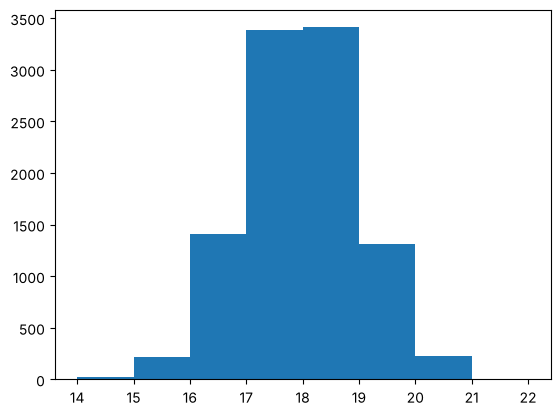

In [18]:
fig, ax = plt.subplots()
ax.hist(lista_numeros, bins = 8)

In [19]:
lista_numeros1 = [random.randint(10, 20) for _ in range(N)]

(array([1825., 1870.,  881., 1820., 1830., 1774.]),
 array([10.        , 11.66666667, 13.33333333, 15.        , 16.66666667,
        18.33333333, 20.        ]),
 <BarContainer object of 6 artists>)

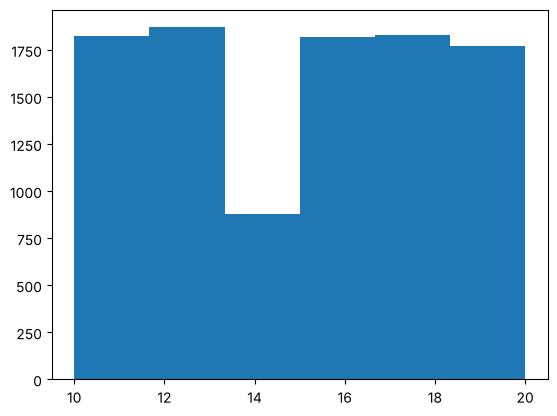

In [20]:
fig, ax = plt.subplots()
ax.hist(lista_numeros1, bins = 6)

## Conclusiones
- `Science_Score` tiene el promedio más alto (86,6) y la menor dispersión (desvío 5,5). `Math_Score` es la materia con más dispersión (desvío 9,1).
- Las correlaciones más fuertes son `Science_Score`–`History_Score` (0,89) y `Age`–`Science_Score` (−0,87). Con solo 5 alumnos, un único caso distinto podría cambiar mucho esos valores: no alcanzan para sacar conclusiones.
- `Student_id` no debe entrar en la matriz de correlación, porque es un identificador y no una medida.
- En los histogramas, `normalvariate` genera la forma de campana alrededor de 18, y `randint` reparte los valores de 10 a 20 de manera pareja (distribución uniforme).